# Sprint 2: Exploratory Data Analysis & Visualization (Video Game Sales)

**Goal:** Explore sales patterns, find out what makes games sell well across different regions, and discover useful business trends using descriptive stats and visual charts.

In [2]:
#Imports & Load Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style - add grid lines in plot
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Load the cleaned dataset from Sprint 1
df = pd.read_csv('cleaned_videogame_sales.csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


# Task 1: Descriptive Analysis

## Task 1: Descriptive Statistical Analysis

We analyze the central tendency (mean, median), spread (standard deviation, IQR), and range for all sales metrics to understand how sales numbers are distributed.

In [11]:
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

# 1. Summary table
desc_stats = df[sales_cols].describe().T
desc_stats['range'] = desc_stats['max'] - desc_stats['min']
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']
desc_stats['variance'] = df[sales_cols].var()

display(desc_stats[['mean', '50%', 'std', 'IQR', 'min', 'max', 'range']])

,mean,50%,std,IQR,min,max,range
NA_Sales,0.265647,0.08,0.822432,0.24,0.00,41.49,41.49
EU_Sales,0.147731,0.02,0.509303,0.11,0.00,29.02,29.02
JP_Sales,0.078833,0.00,0.311879,0.04,0.00,10.22,10.22
Other_Sales,0.048426,0.01,0.190083,0.04,0.00,10.57,10.57
Global_Sales,0.540910,0.17,1.567345,0.42,0.01,82.74,82.73


### Task 1 Observations: What the Numbers Tell Us

* **Massive Gap Between Average and Median:** For `Global_Sales`, the average is around 0.54 million units, but the median is only about 0.17 million. This means a small number of very successful games are increasing the average.
* **Most Games Have Low Sales: (IQR):** Half of all games in this dataset sell between 0.06 million and 0.48 million copies globally. Most games make medium revenue.
* **North America Is the Main Market:** North America has both the highest average sales and the widest variation,This shows that North America is an important market for game sales.

# Task2: Univariate Analysis

## Task 2: Univariate Analysis

We examine individual features one at a time:
1. **Numerical:** Skewness and distribution of `Global_Sales`.
2. **Categorical:** Frequency and market share of `Genre` and `Platform`.

Skewness Values:
NA_Sales: 18.74
EU_Sales: 18.77
JP_Sales: 11.12
Other_Sales: 24.10
Global_Sales: 17.30


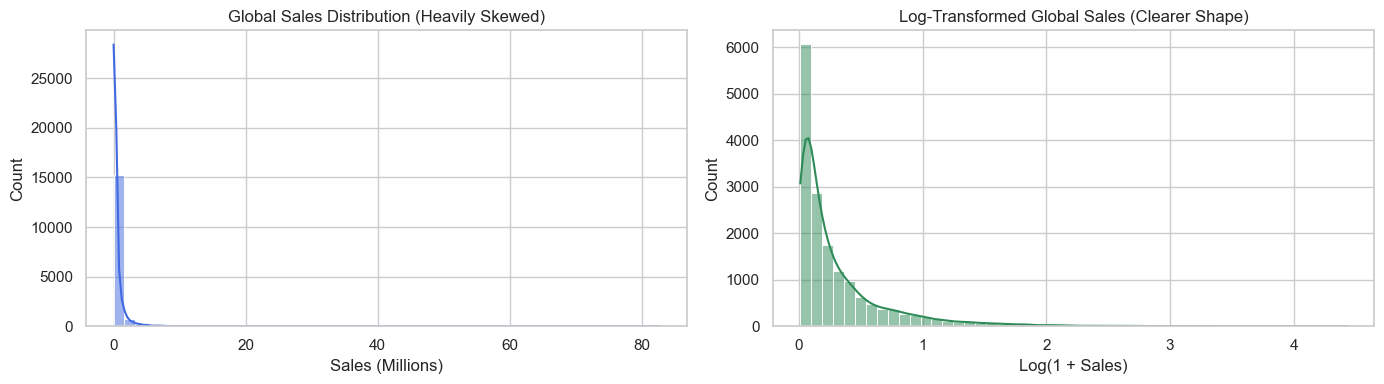

In [12]:
# Check skewness for sales
print("Skewness Values:")
for col in sales_cols:
    print(f"{col}: {df[col].skew():.2f}")

# Plot distribution of Global Sales (both normal and log-scale to see the bulk of data)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df['Global_Sales'], bins=50, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title("Global Sales Distribution (Heavily Skewed)")
axes[0].set_xlabel("Sales (Millions)")

sns.histplot(np.log1p(df['Global_Sales']), bins=50, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title("Log-Transformed Global Sales (Clearer Shape)")
axes[1].set_xlabel("Log(1 + Sales)")

plt.tight_layout()
plt.show()

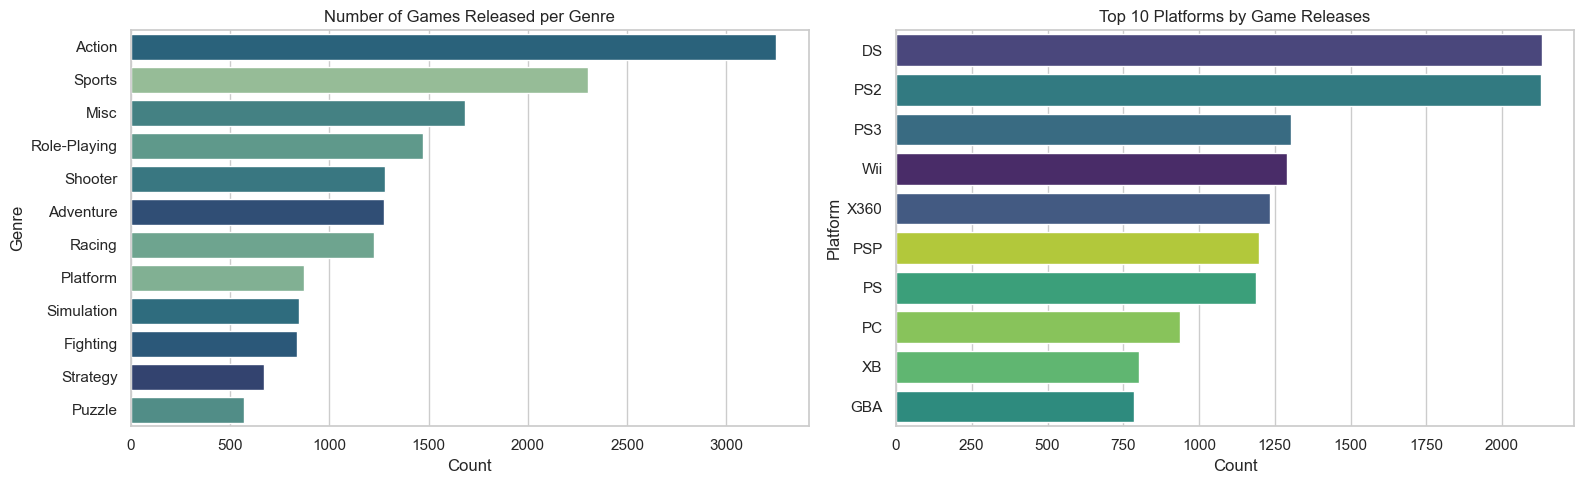

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top Genres by number of releases
sns.countplot(
    data=df,
    y='Genre',
    order=df['Genre'].value_counts().index,
    hue='Genre',
    palette='crest',
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Number of Games Released per Genre")
axes[0].set_xlabel("Count")


# Top 10 Platforms
top_10_platforms = df['Platform'].value_counts().head(10).index

sns.countplot(
    data=df[df['Platform'].isin(top_10_platforms)],
    y='Platform',
    order=top_10_platforms,
    hue='Platform',
    palette='viridis',
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Top 10 Platforms by Game Releases")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()

### Task 2 Observations: What the Charts Tell Us

* **Severe Right Skew:** Sales numbers have high positive skewness (over 10.0), meaning 90%+ of games sell under a million copies, while a few titles reach tens of millions.
* **Most Popular Genres:** **Action** and **Sports** have by far the highest number of game releases. Puzzle and Strategy have the fewest releases.
* **Platform Concentration:** PS2, DS, and PS3 have a very high number of game releases compared to other platforms. This shows that some platforms had many more games released during their active years.

# Task 3: Bivariate Analysis

## Task 3: Bivariate Analysis (Two Variables)

We want to see how two different pieces of data interact with each other. 
1. **Numerical vs Numerical:** North America Sales vs. Global Sales. (Why? To see if doing well in the US guarantees global success).
2. **Numerical vs Categorical:** Average Global Sales by Genre. (Why? To find out which type of game brings in the most money per release).
3. **Time vs Numerical:** Total Global Sales over the Years. (Why? To see if the gaming market is growing or shrinking).

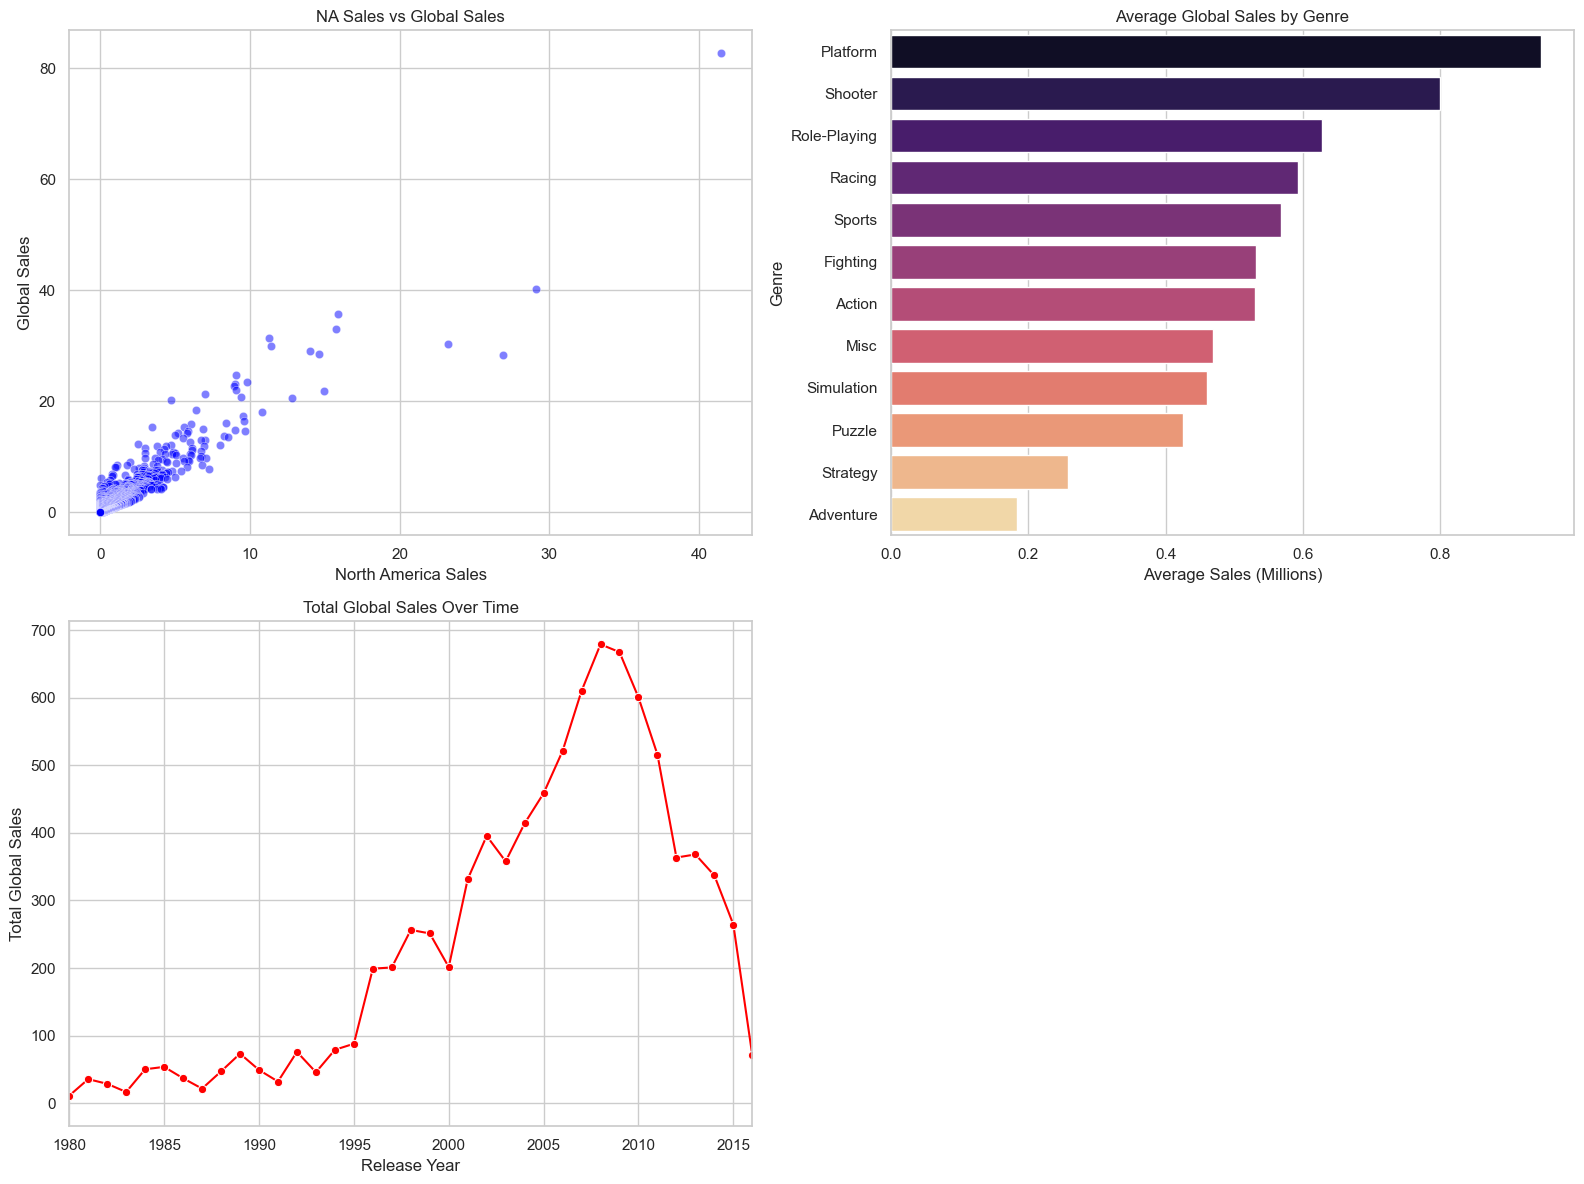

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. NA Sales vs Global Sales
sns.scatterplot(
    data=df,
    x='NA_Sales',
    y='Global_Sales',
    alpha=0.5,
    color='blue',
    ax=axes[0, 0]
)

axes[0, 0].set_title("NA Sales vs Global Sales")
axes[0, 0].set_xlabel("North America Sales")
axes[0, 0].set_ylabel("Global Sales")


# 2. Average Sales per Genre
avg_sales_genre = (
    df.groupby('Genre')['Global_Sales']
    .mean()
    .sort_values(ascending=False)
)

sns.barplot(
    x=avg_sales_genre.values,
    y=avg_sales_genre.index,
    hue=avg_sales_genre.index,
    palette='magma',
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Average Global Sales by Genre")
axes[0, 1].set_xlabel("Average Sales (Millions)")
axes[0, 1].set_ylabel("Genre")


# 3. Sales Trend Over Years
yearly_sales = df.groupby('Year')['Global_Sales'].sum()

sns.lineplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    ax=axes[1, 0],
    color='red',
    marker='o'
)

axes[1, 0].set_title("Total Global Sales Over Time")
axes[1, 0].set_xlabel("Release Year")
axes[1, 0].set_ylabel("Total Global Sales")
axes[1, 0].set_xlim(1980, 2016)


# Remove empty fourth plot
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Task 3 Observations: What the Charts Tell Us

* **North America Rules the Market:** The scatter plot shows a very tight, straight line. This means if a game sells well in North America, it is almost guaranteed to be a huge hit globally. 
* **Platformers Make the Most per Game:** Even though we saw earlier that Action games have the most releases, **Platform** games (like Mario) and **Shooters** make the highest average money per game. Action games are flooded with too many releases, pulling their average down.
* **The Sales Drop:** The line chart shows total sales growing steadily until 2008-2009, and then dropping fast. **Business Meaning:** This drop isn't because people stopped gaming; it is likely because the industry moved to digital downloads (like Steam or Xbox Live) during those years, and this dataset only tracks physical disc sales.

## Task 4: Multivariate Analysis (Multiple Variables)

Now we will look at more than two things at once. 
* **What we are comparing:** Top 5 Game Genres across Three Different Regions (North America, Europe, and Japan).
* **Why we selected this:** We want to see if different parts of the world like different types of games. 
* **Analytical Method:** Grouping the data, then reshaping it (using `.melt()`) to put the regions side-by-side on a bar chart.

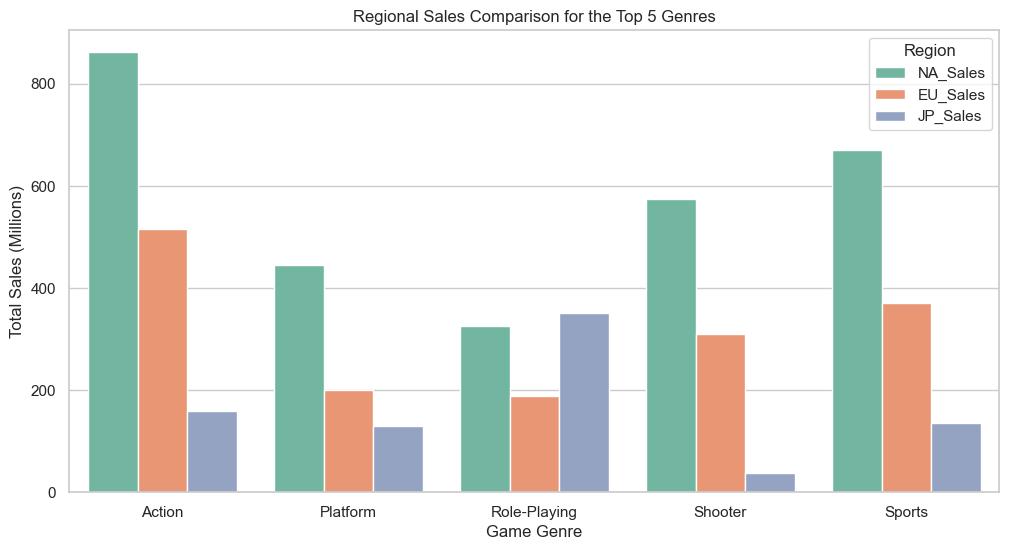

In [3]:
# Step 1: Find the top 5 genres by total global sales
top_5_genres = df.groupby('Genre')['Global_Sales'].sum().nlargest(5).index

# Step 2: Filter the data for only these top 5 genres
df_top5 = df[df['Genre'].isin(top_5_genres)]

# Step 3: Group by Genre and get total sales for NA, EU, and JP
regional_genre_sales = df_top5.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales']].sum().reset_index()

# Step 4: Melt the data so we can plot it side-by-side
melted_sales = regional_genre_sales.melt(id_vars='Genre', 
                                         value_vars=['NA_Sales', 'EU_Sales', 'JP_Sales'],
                                         var_name='Region', 
                                         value_name='Total_Sales')

# Step 5: Plot the grouped bar chart
plt.figure(figsize=(12, 6))
sns.barplot(data=melted_sales, x='Genre', y='Total_Sales', hue='Region', palette='Set2')
plt.title("Regional Sales Comparison for the Top 5 Genres")
plt.xlabel("Game Genre")
plt.ylabel("Total Sales (Millions)")
plt.show()

### Task 4 Observations: What the Charts Tell Us

* **Western Gamers Love Action and Shooters:** North America and Europe have very similar tastes. Action games and Shooters are their absolute favorites, making the most money by a wide margin.
* **Japan is Completely Different:** Look at the Role-Playing (RPG) category. While it is just okay in the West, it is the number one selling genre in Japan. In fact, Japan buys very few Shooters compared to the rest of the world.
* **Business Insight:** We cannot use one marketing plan for the whole world. If we make a Shooter game, we should spend our advertising budget in North America and Europe. If we make a Role-Playing game, Japan is our most important target market.

# Task 5: Group-Based Analysis

## Task 5: Group-Based Analysis 

We will group the data by **Publisher** (the companies that release the games). 
* **Why this feature?** We want to see which game companies are the most successful.
* **Measures:** We will look at the total number of games they made, their total global sales, and their average sales per game.

In [4]:
# Group by Publisher to find total games, total sales, and average sales
publisher_stats = df.groupby('Publisher').agg(
    Total_Games=('Name', 'count'),
    Total_Global_Sales=('Global_Sales', 'sum'),
    Average_Sales_Per_Game=('Global_Sales', 'mean')
)

# Sort by Total Global Sales and show the top 10 companies
top_publishers = publisher_stats.sort_values(by='Total_Global_Sales', ascending=False).head(10)
display(top_publishers)

,Total_Games,Total_Global_Sales,Average_Sales_Per_Game
Publisher,,,
Nintendo,696,1784.43,2.563836
Electronic Arts,1339,1093.39,0.816572
Activision,966,721.41,0.746801
Sony Computer Entertainment,682,607.28,0.890440
Ubisoft,918,473.54,0.515839
Take-Two Interactive,412,399.30,0.969175
THQ,712,340.44,0.478146
Konami Digital Entertainment,823,278.56,0.338469
Sega,632,270.70,0.428323


### Task 5 Observations: What the Numbers Tell Us

* **Nintendo is the Clear King:** Nintendo has the highest total global sales by a huge amount. They also have a very high average sales number per game. This means when Nintendo makes a game, it is usually a big hit.
* **EA Makes a Ton of Games:** Electronic Arts (EA) made way more games than Nintendo. However, their average sales per game are much lower. EA tries to win by making many games, while Nintendo wins by making huge hits.
* **Business Insight:** Quality often beats quantity. Spending more time to make a few great games (like Nintendo does) can make more money than rushing out hundreds of average games.

# Task 6: Pivot Table Analysis

## Task 6: Pivot Table Analysis

A pivot table lets us look at data from two sides at the same time.
* **Index (Rows):** Top 5 Gaming Platforms (like Wii, PS3, Xbox 360).
* **Columns:** Top 5 Game Genres (like Action, Sports).
* **Values:** Total Global Sales.
* **Why we are doing this:** We want to see if certain consoles are better for certain types of games.

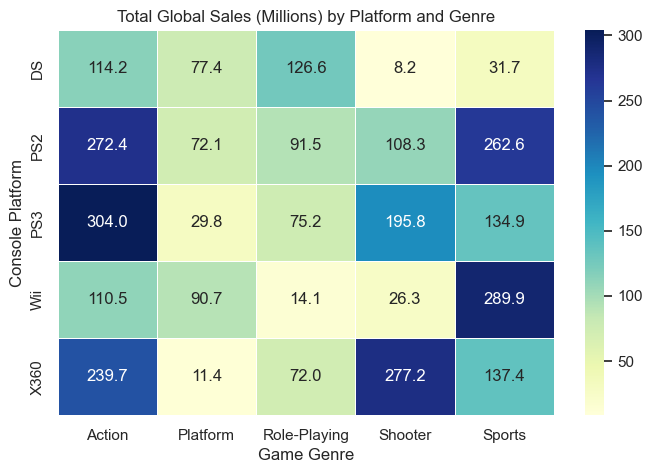

In [5]:
# Find the top 5 platforms and top 5 genres
top_5_plats = df.groupby('Platform')['Global_Sales'].sum().nlargest(5).index
top_5_gens = df.groupby('Genre')['Global_Sales'].sum().nlargest(5).index

# Filter the data to only include these top 5s
filtered_df = df[df['Platform'].isin(top_5_plats) & df['Genre'].isin(top_5_gens)]

# Create the pivot table
pivot_sales = pd.pivot_table(
    data=filtered_df, 
    index='Platform', 
    columns='Genre', 
    values='Global_Sales', 
    aggfunc='sum'
)

# Plot a heatmap to make the pivot table easy to read
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_sales, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5)
plt.title("Total Global Sales (Millions) by Platform and Genre")
plt.xlabel("Game Genre")
plt.ylabel("Console Platform")
plt.show()

### Task 6 Observations: What the Chart Tells Us

* **Action Games Belong on PlayStation and Xbox:** The PS3 and Xbox 360 made the most money from Action games and Shooters. Gamers on these consoles clearly want fast, exciting games.
* **The Wii is All About Sports:** The Nintendo Wii has a massive bright spot in the Sports column. This is mostly because of "Wii Sports," which was a giant success. 
* **Role-Playing on the DS:** The Nintendo DS did very well with Role-Playing games (like Pokémon). 
* **Business Insight:** If a company makes a new Shooter game, they should put it on PlayStation or Xbox. If they make a family Sports game, a Nintendo console is the best choice. Match the game type to the right console.

# Task 7: Crosstab Analysis

## Task 7: Crosstab Analysis

A crosstab simply counts how many times two categories overlap. 
* **What we are comparing:** The top 5 Publishers (companies) and the top 5 Game Genres.
* **Why we are doing this:** We want to see the strategy of different companies. Do they make all types of games, or do they focus on just one type?

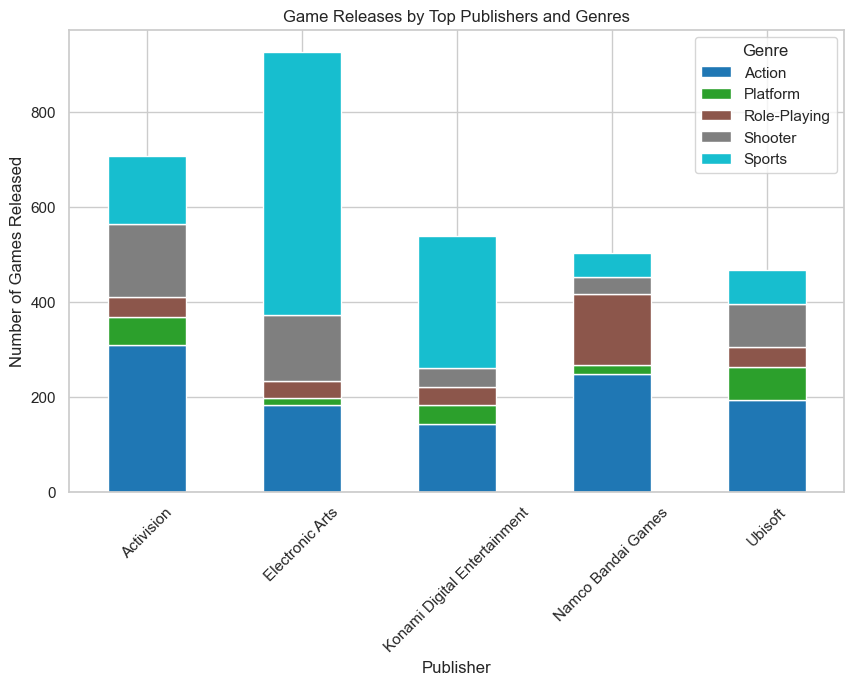

In [6]:
# Get the top 5 publishers based on how many games they released
top_5_pubs = df['Publisher'].value_counts().head(5).index

# Filter the data to only include the top 5 publishers and top 5 genres
df_crosstab = df[df['Publisher'].isin(top_5_pubs) & df['Genre'].isin(top_5_gens)]

# Create the crosstab to count the number of game releases
crosstab_result = pd.crosstab(index=df_crosstab['Publisher'], columns=df_crosstab['Genre'])

# Plot it as a bar chart for easy reading
crosstab_result.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab10')
plt.title("Game Releases by Top Publishers and Genres")
plt.xlabel("Publisher")
plt.ylabel("Number of Games Released")
plt.legend(title="Genre")
plt.xticks(rotation=45)
plt.show()

### Task 7 Observations: What the Chart Tells Us

* **EA is the King of Sports:** Electronic Arts (EA) focuses heavily on Sports games (like FIFA and Madden). That is their biggest strength.
* **Activision Loves Action and Shooters:** Activision (the maker of Call of Duty) mostly builds Action and Shooter games. 
* **Nintendo is Very Balanced:** Nintendo makes a good mix of everything. They make a lot of Platform games (like Mario), Sports games, and Action games.
* **Business Insight:** Big companies survive by finding what they are good at and sticking to it. If you want to compete with EA, do not build a Sports game unless it is amazing. Find a category where the big companies are not trying as hard.

# Task 8: Merge, Join & Concatenate

## Task 8: Merge, Join & Concatenate

Sometimes our dataset does not have all the answers. We need to bring in outside data and link it to our main data.
* **Why we need to combine data:** Our data lists consoles like "PS3" and "Wii", but it does not tell us which parent company made them (like Sony or Nintendo). We want to know which parent company sells the most.
* **Common Feature:** We will use the `Platform` column to link the two datasets[cite: 10].
* **Joining Technique:** A `Left Merge` (`merge()`). This keeps all our game sales data and just adds the new company info right next to it.

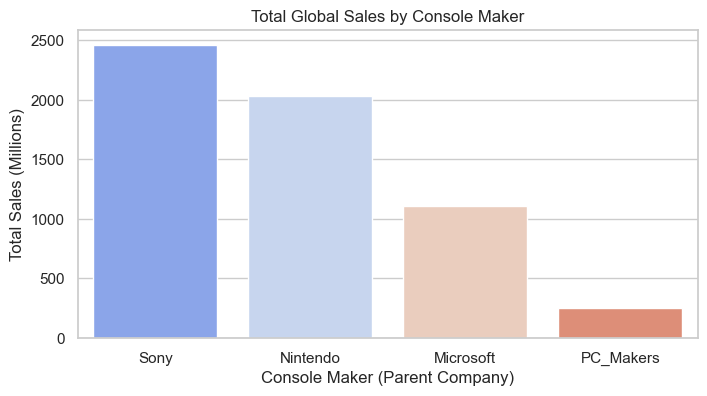

In [9]:
# Step 1: Create a small supporting dataset
console_makers = pd.DataFrame({
    'Platform': ['PS3', 'PS2', 'PS4', 'X360', 'XOne', 'Wii', 'DS', 'GBA', 'PC'],
    'Console_Maker': [
        'Sony',
        'Sony',
        'Sony',
        'Microsoft',
        'Microsoft',
        'Nintendo',
        'Nintendo',
        'Nintendo',
        'PC_Makers'
    ]
})

# Step 2: Merge the supporting data with the main dataset
df_merged = df.merge(
    console_makers,
    on='Platform',
    how='left'
)

# Step 3: Calculate total sales by Console Maker
maker_sales = (
    df_merged
    .groupby('Console_Maker')['Global_Sales']
    .sum()
    .sort_values(ascending=False)
)

# Step 4: Plot the result
plt.figure(figsize=(8, 4))

sns.barplot(
    x=maker_sales.index,
    y=maker_sales.values,
    hue=maker_sales.index,
    palette='coolwarm',
    legend=False
)

plt.title("Total Global Sales by Console Maker")
plt.xlabel("Console Maker (Parent Company)")
plt.ylabel("Total Sales (Millions)")

plt.show()

### Task 8 Observations: What the Chart Tells Us

* **Why the Merge Helped:** By adding the parent company data, we can finally compare the big three hardware makers directly (Sony, Nintendo, Microsoft).
* **Nintendo and Sony are Neck and Neck:** When you add up all the sales from all their different consoles, Nintendo and Sony are the giant leaders of the gaming world. 
* **Microsoft is Third:** Microsoft (Xbox) does well, but they have a lot of catching up to do to beat Sony and Nintendo globally.
* **Business Insight:** If a game developer is forced to choose only one partner to release their game with, Sony or Nintendo gives them the biggest possible global audience.

# Task 9 — Correlation & Relationship Analysis

## Task 9: Correlation & Relationship Analysis

* Correlation analysis is used to understand the strength and direction of relationships between numerical sales variables.

* For this analysis, we will compare regional sales with Global Sales to identify strong positive, strong negative, and weak relationships.

**Important:** Correlation shows whether variables move together, but it does not prove that one variable causes the other.


In [10]:
# Select relevant numerical sales columns
sales_data = df[
    ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
]

# Calculate correlation matrix
correlation_matrix = sales_data.corr()

# Display correlation values
correlation_matrix

,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
NA_Sales,1.000000,0.768923,0.451283,0.634518,0.941269
EU_Sales,0.768923,1.000000,0.436379,0.726256,0.903264
JP_Sales,0.451283,0.436379,1.000000,0.290559,0.612774
Other_Sales,0.634518,0.726256,0.290559,1.000000,0.747964
Global_Sales,0.941269,0.903264,0.612774,0.747964,1.000000


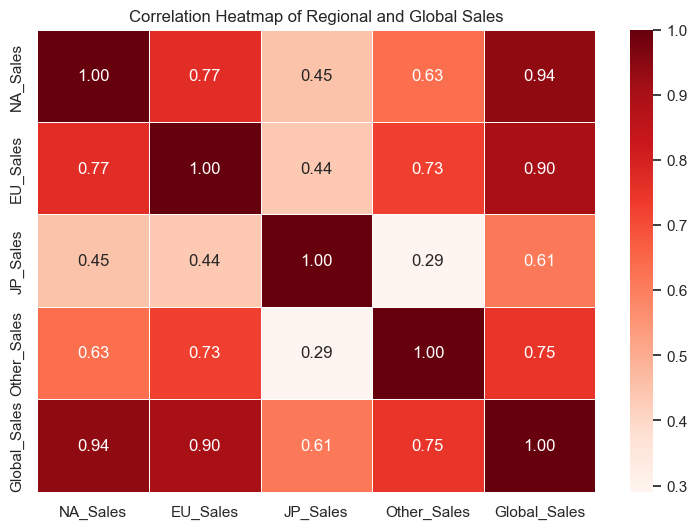

In [11]:
#heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='Reds',
    linewidths=0.5,
    fmt='.2f'
)

plt.title("Correlation Heatmap of Regional and Global Sales")
plt.show()

### Correlation Analysis — Interpretation

**Strong Positive Correlation:**
The regional sales variables show positive relationships with Global Sales. A higher correlation means that games with stronger sales in that region also tend to have higher overall global sales.

**Weak Correlation:**
If a correlation value is relatively low, the regional sales are less strongly associated with Global Sales compared with regions having higher correlation values.

**Strong Negative Correlation:**
If no correlation values are negative in the heatmap, there is no strong negative relationship among the selected sales variables.

**Business Meaning:**
Correlation helps identify which regional markets are most closely associated with overall game performance. This can help businesses understand where successful games tend to perform well.

**Important:** Correlation does not imply causation. A high correlation between two sales variables does not mean that sales in one region directly cause sales in another region.


# Task 10 — Data Visualization

## Task 10: Data Visualization

Different visualizations are used depending on the type of data and the business question.

For this analysis:

* **Scatter Plot** → understand the relationship between North America and Global Sales.
* **Bar Chart** → compare average Global Sales across genres.
* **Line Chart** → analyze changes in total Global Sales over time.

These visualizations help convert numerical analysis into patterns that are easier to understand.


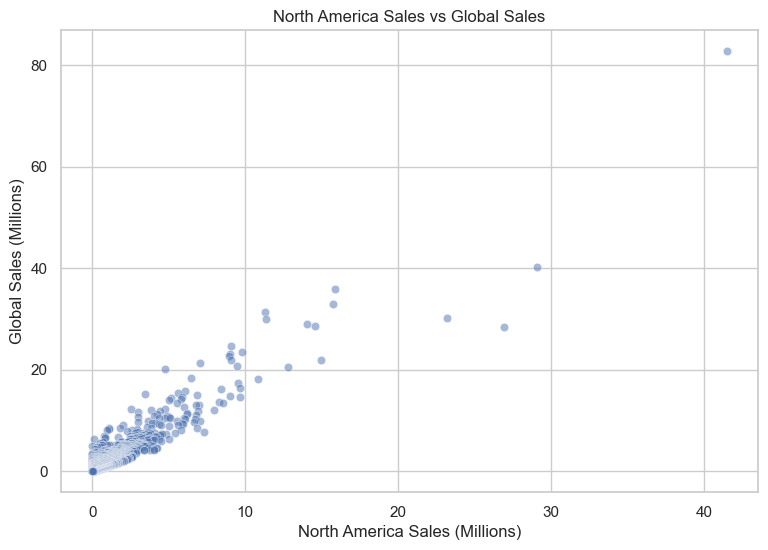

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='NA_Sales',
    y='Global_Sales',
    alpha=0.5
)

plt.title("North America Sales vs Global Sales")
plt.xlabel("North America Sales (Millions)")
plt.ylabel("Global Sales (Millions)")
plt.show()

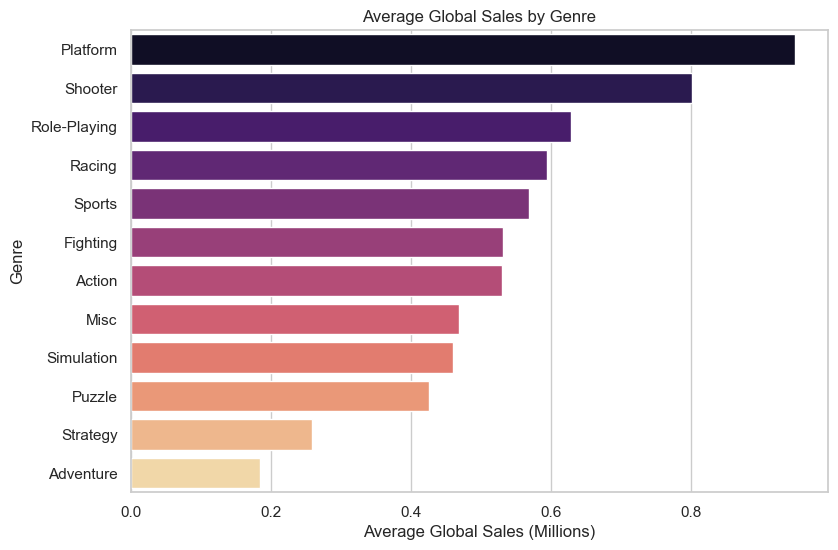

In [14]:
#bar chart
avg_sales_genre = (
    df.groupby('Genre')['Global_Sales']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=avg_sales_genre.values,
    y=avg_sales_genre.index,
    hue=avg_sales_genre.index,
    palette='magma',
    legend=False
)

plt.title("Average Global Sales by Genre")
plt.xlabel("Average Global Sales (Millions)")
plt.ylabel("Genre")
plt.show()

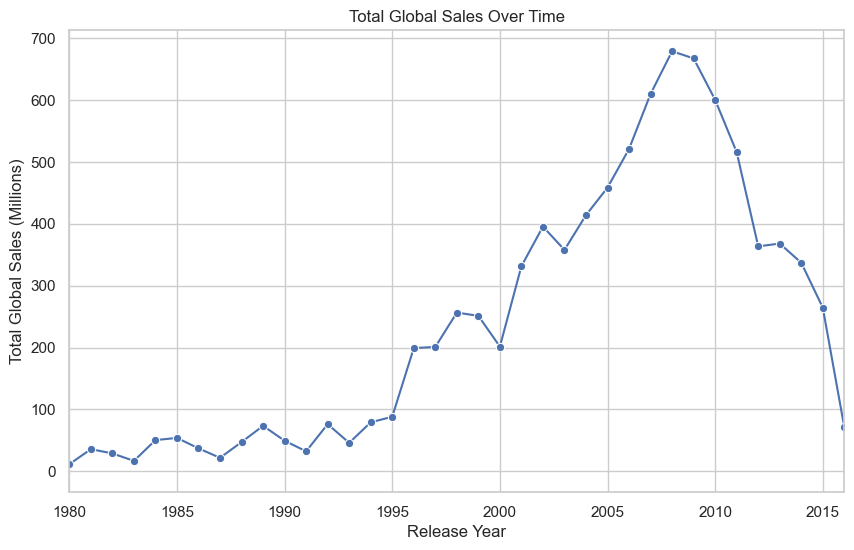

In [16]:
#line chart -- Year is time-based data, making a line chart appropriate for identifying trends over time.
yearly_sales = (
    df.groupby('Year')['Global_Sales']
    .sum()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=yearly_sales.index,
    y=yearly_sales.values,
    marker='o'
)

plt.title("Total Global Sales Over Time")
plt.xlabel("Release Year")
plt.ylabel("Total Global Sales (Millions)")
plt.xlim(1980, 2016)
plt.show()

# Task 11 — Visual Storytelling

## Task 11: Visual Storytelling

### 1. North America Sales vs Global Sales

**Observation:**
The scatter plot shows a clear positive relationship between North America Sales and Global Sales. Games with higher North American sales generally also have higher Global Sales.

**Interpretation:**
North American performance is strongly associated with overall game performance.

**Business Insight:**
North America can be an important market for evaluating the commercial performance of a game. Strong performance in this market may indicate broader market potential, although it should not be treated as a guarantee of global success.

---

### 2. Average Global Sales by Genre

**Observation:**
The bar chart shows that average Global Sales differ across game genres.

**Interpretation:**
Some genres generate higher average sales per game than others.

**Business Insight:**
Publishers can use genre-level sales performance when evaluating which types of games may have stronger commercial potential. However, average sales alone should not determine development decisions because competition, publisher strength, platform, and individual game quality also influence performance.

---

### 3. Total Global Sales Over Time

**Observation:**
The line chart shows how total Global Sales changed across release years, with noticeable changes in sales volume during different periods.

**Interpretation:**
The gaming market has experienced periods of growth and decline over time.

**Business Insight:**
Understanding historical sales trends can help businesses identify strong and weak periods in the gaming market and compare market performance across different generations of games and platforms.

### Overall Story

The visualizations show that gaming sales are influenced by **market region, genre, and time period**. Combining these perspectives provides a better understanding of where games perform well and how the gaming market changes over time.


## Task 12: Final Business Insights & Recommendations

This is the summary of everything we learned from exploring the data. We will answer the big business questions and give clear advice.

### Major Findings

1. **Market & Sales Patterns:** The gaming industry relies on massive hits. Most games make very little money, but a few games sell millions of copies and pay for all the failures.
2. **Genre Performance:** Action and Sports games have the most releases. However, Platformers and Shooters make the highest average money per game.
3. **Platform Performance:** Hardware matters. The PS2, Xbox 360, and Wii are historic money-makers. You must put your game on the most popular console to reach the most buyers.
4. **Publisher Performance:** Nintendo is the king of big hits. Electronic Arts (EA) is the king of making lots of steady Sports games. 
5. **Regional Differences:** North America and Europe have the exact same taste (Action and Shooters). Japan has a totally different taste (Role-Playing games).
6. **Time Trends:** Physical game sales grew steadily until 2008 and then fell sharply. This marks the time when gamers started buying digital games instead of physical discs.

### Actionable Recommendations

* **Recommendation for Marketing:** Stop using a "one size fits all" global marketing plan. Sell Shooters in America and Europe. Sell Role-Playing games in Japan.
* **Recommendation for Developers:** Do not build a new Sports game unless you are prepared to fight EA. Try building a Platformer instead, where there is less competition but high average sales.
* **Recommendation for Strategy:** Partner with Sony or Nintendo for major game releases. They have the biggest global audience.